In [16]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [17]:
load_dotenv()

True

In [18]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

In [19]:
# REducer state
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [20]:
def chat_node(state: ChatState):
    #take user query from state
    messages = state['messages']
    # send to llm
    response = llm.invoke(messages)
    # response store state
    return {'messages': [response]}

In [21]:
checkpoint = MemorySaver()

graph = StateGraph(ChatState)

# add nodes
graph.add_node('chat_node', chat_node)

#add edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)


chatbot = graph.compile(checkpointer=checkpoint)
# chatbot = graph.compile()


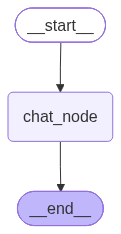

In [8]:
chatbot

In [ ]:
# thread_id = "2"
# initial_state = {
#     'messages': [HumanMessage(content='what is oops?')]
# }

# config = {'configurable': {'thread_id': thread_id}}
# response = chatbot.invoke(initial_state, config=config)
# response = chatbot.invoke(initial_state)



In [ ]:
# print(response)

{'messages': [HumanMessage(content='what is oops?', additional_kwargs={}, response_metadata={}, id='043f7182-8b4e-4255-80c4-fcf4638a0e26'), AIMessage(content='**OOPs** is a playful shorthand for **Object‑Oriented Programming (OOP)**, a programming paradigm that organizes software around “objects” rather than functions or logic.  \nBelow is a quick primer on what OOP is, why it matters, and how it’s used in practice.\n\n---\n\n## 1. What is Object‑Oriented Programming?\n\nOOP is a way of structuring code so that data and the operations that act on that data are bundled together into **objects**.  \nThe core principles that make OOP powerful are:\n\n| Principle | What it means | Why it matters |\n|-----------|---------------|----------------|\n| **Encapsulation** | Keep data (state) and the code that manipulates it (methods) together in a single unit. | Protects data from unintended interference; makes code easier to maintain. |\n| **Abstraction** | Expose only what’s necessary; hide imp

In [ ]:
# response['messages'][-1].content


'**OOPs** is a playful shorthand for **Object‑Oriented Programming (OOP)**, a programming paradigm that organizes software around “objects” rather than functions or logic.  \nBelow is a quick primer on what OOP is, why it matters, and how it’s used in practice.\n\n---\n\n## 1. What is Object‑Oriented Programming?\n\nOOP is a way of structuring code so that data and the operations that act on that data are bundled together into **objects**.  \nThe core principles that make OOP powerful are:\n\n| Principle | What it means | Why it matters |\n|-----------|---------------|----------------|\n| **Encapsulation** | Keep data (state) and the code that manipulates it (methods) together in a single unit. | Protects data from unintended interference; makes code easier to maintain. |\n| **Abstraction** | Expose only what’s necessary; hide implementation details. | Simplifies complex systems by focusing on high‑level concepts. |\n| **Inheritance** | Create new classes that reuse, extend, or modify 

In [ ]:
# chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='what is oops?', additional_kwargs={}, response_metadata={}, id='043f7182-8b4e-4255-80c4-fcf4638a0e26'), AIMessage(content='**OOPs** is a playful shorthand for **Object‑Oriented Programming (OOP)**, a programming paradigm that organizes software around “objects” rather than functions or logic.  \nBelow is a quick primer on what OOP is, why it matters, and how it’s used in practice.\n\n---\n\n## 1. What is Object‑Oriented Programming?\n\nOOP is a way of structuring code so that data and the operations that act on that data are bundled together into **objects**.  \nThe core principles that make OOP powerful are:\n\n| Principle | What it means | Why it matters |\n|-----------|---------------|----------------|\n| **Encapsulation** | Keep data (state) and the code that manipulates it (methods) together in a single unit. | Protects data from unintended interference; makes code easier to maintain. |\n| **Abstraction** | Expose only what’

In [ ]:
# list(chatbot.get_state_history(config=config))

[StateSnapshot(values={'messages': [HumanMessage(content='what is oops?', additional_kwargs={}, response_metadata={}, id='043f7182-8b4e-4255-80c4-fcf4638a0e26'), AIMessage(content='**OOPs** is a playful shorthand for **Object‑Oriented Programming (OOP)**, a programming paradigm that organizes software around “objects” rather than functions or logic.  \nBelow is a quick primer on what OOP is, why it matters, and how it’s used in practice.\n\n---\n\n## 1. What is Object‑Oriented Programming?\n\nOOP is a way of structuring code so that data and the operations that act on that data are bundled together into **objects**.  \nThe core principles that make OOP powerful are:\n\n| Principle | What it means | Why it matters |\n|-----------|---------------|----------------|\n| **Encapsulation** | Keep data (state) and the code that manipulates it (methods) together in a single unit. | Protects data from unintended interference; makes code easier to maintain. |\n| **Abstraction** | Expose only what

In [32]:


thread_id = "4"

while True:
    user_message = input('Type here: ')

    print('User:', user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable': {'thread_id': thread_id}}
    
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)
    # response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]})
    print("response",response)
    print('AI:', response['messages'][-1].content)

User: explain python in one word
response {'messages': [HumanMessage(content='explain python in one word', additional_kwargs={}, response_metadata={}, id='ec645c33-dd9d-4e4a-988c-10f241d70b74'), AIMessage(content='Readable', additional_kwargs={'reasoning_content': 'The user says: "explain python in one word". They want a single word that explains Python. We need to respond with one word. But maybe we can add a brief explanation? The instruction says "explain python in one word". So likely they want a single word. But we could also add a brief explanation? The instruction is ambiguous. The user says "explain python in one word". That could be interpreted as "give me a one-word explanation of Python". So we should respond with a single word. But maybe we can add a short explanation? The instruction says "explain python in one word". So we should just give one word. But maybe we can add a short explanation after? The user didn\'t ask for more. So we should just give one word. But we might

In [33]:
chatbot.get_state(config=config)


StateSnapshot(values={'messages': [HumanMessage(content='explain python in one word', additional_kwargs={}, response_metadata={}, id='ec645c33-dd9d-4e4a-988c-10f241d70b74'), AIMessage(content='Readable', additional_kwargs={'reasoning_content': 'The user says: "explain python in one word". They want a single word that explains Python. We need to respond with one word. But maybe we can add a brief explanation? The instruction says "explain python in one word". So likely they want a single word. But we could also add a brief explanation? The instruction is ambiguous. The user says "explain python in one word". That could be interpreted as "give me a one-word explanation of Python". So we should respond with a single word. But maybe we can add a short explanation? The instruction says "explain python in one word". So we should just give one word. But maybe we can add a short explanation after? The user didn\'t ask for more. So we should just give one word. But we might want to be safe: "Ve

In [34]:
list(chatbot.get_state_history(config=config))

[StateSnapshot(values={'messages': [HumanMessage(content='explain python in one word', additional_kwargs={}, response_metadata={}, id='ec645c33-dd9d-4e4a-988c-10f241d70b74'), AIMessage(content='Readable', additional_kwargs={'reasoning_content': 'The user says: "explain python in one word". They want a single word that explains Python. We need to respond with one word. But maybe we can add a brief explanation? The instruction says "explain python in one word". So likely they want a single word. But we could also add a brief explanation? The instruction is ambiguous. The user says "explain python in one word". That could be interpreted as "give me a one-word explanation of Python". So we should respond with a single word. But maybe we can add a short explanation? The instruction says "explain python in one word". So we should just give one word. But maybe we can add a short explanation after? The user didn\'t ask for more. So we should just give one word. But we might want to be safe: "V